# Заняття 12 · Demo 2 — реєстрація RGB ↔ LWIR

Та сама установка, що в Demo 1: RGB 1280×720 (HFOV 60°, f ≈ 1108 px) і LWIR 640×512 (HFOV 45°, f ≈ 773 px),
тепловізор на 5 см праворуч і 1 см нижче, вісь розвернута на 0.40° / −0.25° / 0.10° (yaw / pitch / roll).
`T_rgb_t` відомо точно — тому залишок реєстрації міряємо в кожному пікселі, а не «на око».

1. Рамки і тест «на нескінченності» (як «10 м попереду» на занятті 11).
2. `H∞ = K_rgb · R · K_t⁻¹`: залишок проти `f·B/Z` на 8 / 18 / 45 / 75 м.
3. Гомографія площини: точна лише на одній глибині.
4. Реєстрація з глибиною (LiDAR / стерео із заняття 11).
5. Калібрування підігрітою мішенню: RMS у px не доводить нічого — перевіряємо на ближніх і далеких.
6. Крос-модальні відповідності: ORB і NCC ламаються, mutual information — ні; те саме на реальних парах LLVIP і FLIR-aligned
   і скільки залишкової розбіжності в «вирівняних» датасетах.
7. Час: `f·ω·Δt` і пари кадрів за мітками.

In [1]:
%matplotlib inline
import sys, numpy as np, matplotlib.pyplot as plt, ipywidgets as W, cv2
from pathlib import Path
from scipy.spatial.transform import Rotation as Rot
sys.path.insert(0, str(Path.cwd()))
import sim12 as S, panels as P
plt.rcParams['figure.dpi'] = 90
B = np.linalg.norm(S.BASELINE[:2])

## 1. Рамки і тест «на нескінченності»
Конвенція `T_to_from` із заняття 11: `T_rgb_t` переводить точки з рамки тепловізора в рамку RGB.
Юніт-тест: точка на оптичній осі T на 10 км має лягти в RGB у `K_rgb · R · [0, 0, 1]ᵀ` — трансляція там не важить.

In [2]:
for cam in (S.RGB_CAM, S.T_CAM):
    print(f'{cam.name:4s}: {cam.W}×{cam.H}, HFOV {cam.hfov:.0f}°, f = {cam.f:7.1f} px, IFOV = {cam.ifov_deg * 60:.2f}′/px')
print(f'кутова роздільність різна в {S.T_CAM.ifov_deg / S.RGB_CAM.ifov_deg:.2f}×: один T-піксель ≈ '
      f'{S.T_CAM.ifov_deg / S.RGB_CAM.ifov_deg:.2f} RGB-пікселя')
X_t = np.array([[0, 0, 1e4]])                      # 10 км на осі тепловізора
u, v, z, m = S.project(S.transform(S.T_RGB_T, X_t), S.RGB_CAM.K, S.RGB_CAM.W, S.RGB_CAM.H)
d = S.RGB_CAM.K @ S.T_RGB_T[:3, :3] @ [0, 0, 1]
print(f'вісь T на 10 км → RGB (u, v) = ({u[0]:.2f}, {v[0]:.2f}); прогноз K·R·e_z = ({d[0] / d[2]:.2f}, {d[1] / d[2]:.2f}); '
      f'центр RGB = ({S.RGB_CAM.K[0, 2]:.1f}, {S.RGB_CAM.K[1, 2]:.1f})')
print(f'boresight 0.40° yaw = {S.RGB_CAM.f * np.tan(np.radians(0.4)):.1f} px RGB — більше за паралакс на 18 м')
assert abs(u[0] - d[0] / d[2]) < 0.01

RGB : 1280×720, HFOV 60°, f =  1108.5 px, IFOV = 2.81′/px
LWIR: 640×512, HFOV 45°, f =   772.5 px, IFOV = 4.22′/px
кутова роздільність різна в 1.50×: один T-піксель ≈ 1.50 RGB-пікселя
вісь T на 10 км → RGB (u, v) = (647.24, 364.35); прогноз K·R·e_z = (647.23, 364.35); центр RGB = (639.5, 359.5)
boresight 0.40° yaw = 7.7 px RGB — більше за паралакс на 18 м


## 2. `H∞`: уся сцена «на нескінченності»
Слайд «Реєстрація · паралакс». Залишок `H∞` у кожному пікселі має збігатися з `f·B/Z`.

об’єкт         Z, м  залишок H∞, px  f·B/Z, px
людина 8 м      8.0            7.07       7.07
людина 18 м    18.0            3.14       3.14
авто           25.0            2.26       2.26
людина 45 м    45.0            1.26       1.26
дрон           60.0            0.94       0.94
стіна          75.0            0.75       0.75


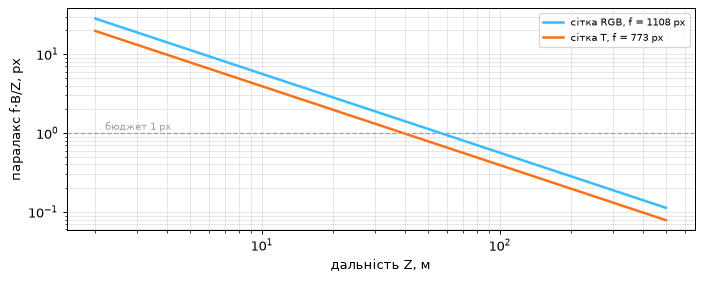

f = 1108.5 px: паралакс < 1 px з Z >  56.5 м
f =  772.5 px: паралакс < 1 px з Z >  39.4 м


In [3]:
hour = 9.0
rgb = S.render_rgb(hour); core = S.Core(); raw, _, _ = S.render_thermal(hour, core)
t8 = S.agc(raw, 'percentile').astype(np.float32)
D = S.rgb_depth()
res_inf = S.registration_residual(S.H_inf(), D)
print(f'{"об’єкт":12s} {"Z, м":>6s} {"залишок H∞, px":>15s} {"f·B/Z, px":>10s}')
for name in ('людина 8 м', 'людина 18 м', 'авто', 'людина 45 м', 'дрон', 'стіна'):
    m = S.object_px(name) & np.isfinite(res_inf)
    print(f'{name:12s} {np.median(D[m]):6.1f} {np.median(res_inf[m]):15.2f} {S.parallax_px(S.RGB_CAM.f, B, np.median(D[m])):10.2f}')
Z = np.geomspace(2, 500, 200)
fig, ax = plt.subplots(figsize=(9, 3.2))
for f, name, c in ((S.RGB_CAM.f, 'сітка RGB, f = 1108 px', P.C_RGB), (S.T_CAM.f, 'сітка T, f = 773 px', P.C_T)):
    ax.loglog(Z, S.parallax_px(f, B, Z), color=c, lw=2, label=name)
ax.axhline(1, color=P.C_W, ls='--', lw=1); ax.text(2.2, 1.1, 'бюджет 1 px', color=P.C_W, fontsize=8)
ax.set_xlabel('дальність Z, м'); ax.set_ylabel('паралакс f·B/Z, px'); ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=8)
plt.show()
for f in (S.RGB_CAM.f, S.T_CAM.f):
    print(f'f = {f:6.1f} px: паралакс < 1 px з Z > {f * B:5.1f} м')

In [4]:
P.registration_panel();

interactive(children=(Dropdown(description='method', options=('H∞', 'H площини Z0', 'глибина (LiDAR / стерео)'…

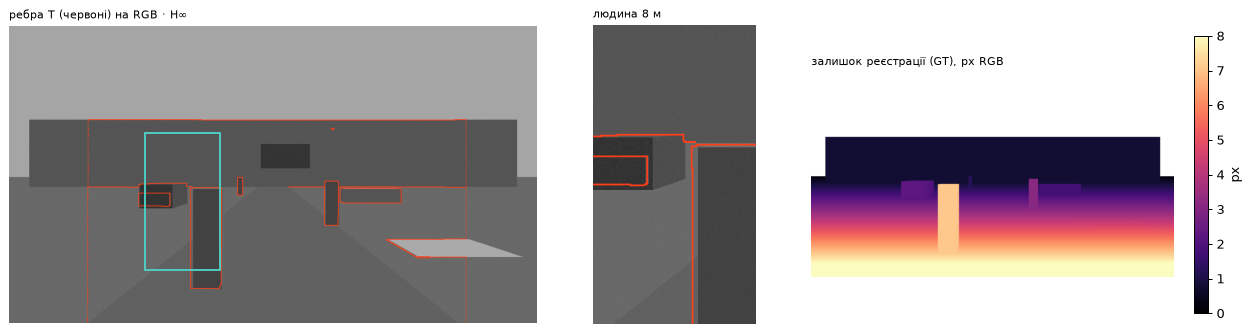

людина 8 м   Z =   8.0 м: залишок  7.07 px, f·B/Z =  7.07 px
людина 18 м  Z =  18.0 м: залишок  3.14 px, f·B/Z =  3.14 px
людина 45 м  Z =  45.0 м: залишок  1.26 px, f·B/Z =  1.26 px
дрон         Z =  60.0 м: залишок  0.94 px, f·B/Z =  0.94 px
стіна        Z =  75.0 м: залишок  0.75 px, f·B/Z =  0.75 px


In [5]:
P.registration_panel(static=dict(method='H∞', Z0=18.0, crop='людина 8 м'))

## 3. Гомографія площини `H = K_rgb (R + t·nᵀ / Z0) K_t⁻¹`
Точна для однієї площини. Обираємо Z0 = 18 м — людина на 18 м лягає ідеально, ближні й далекі — ні.

In [6]:
print(f'{"Z0, м":>6s} | ' + ' | '.join(f'{n:>11s}' for n in ('людина 8 м', 'людина 18 м', 'людина 45 м', 'стіна')))
for Z0 in (8.0, 18.0, 45.0, 1e6):
    r = S.registration_residual(S.H_plane(Z0), D)
    vals = [np.median(r[S.object_px(n) & np.isfinite(r)]) for n in ('людина 8 м', 'людина 18 м', 'людина 45 м', 'стіна')]
    print(f'{"∞" if Z0 > 1e5 else f"{Z0:.0f}":>6s} | ' + ' | '.join(f'{x:11.2f}' for x in vals))

 Z0, м |  людина 8 м | людина 18 м | людина 45 м |       стіна
     8 |        0.00 |        3.93 |        5.81 |        6.31
    18 |        3.93 |        0.00 |        1.88 |        2.39


    45 |        5.81 |        1.88 |        0.00 |        0.50
     ∞ |        7.07 |        3.14 |        1.26 |        0.75


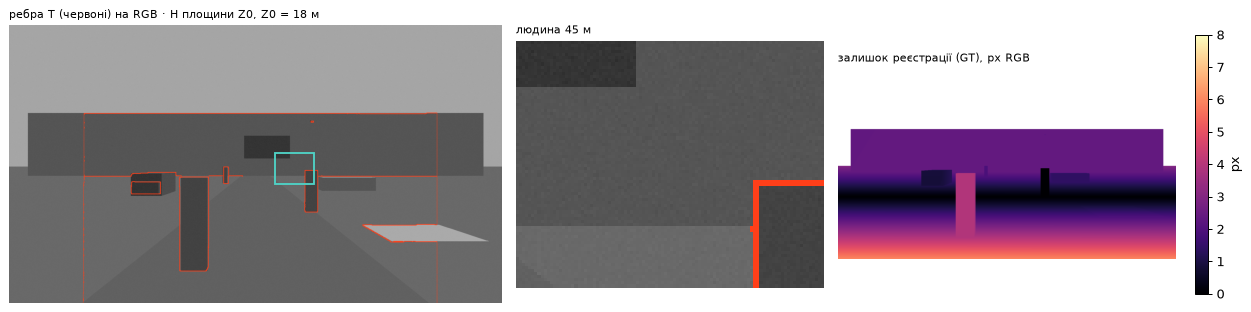

людина 8 м   Z =   8.0 м: залишок  3.93 px, f·B/Z =  7.07 px
людина 18 м  Z =  18.0 м: залишок  0.00 px, f·B/Z =  3.14 px
людина 45 м  Z =  45.0 м: залишок  1.88 px, f·B/Z =  1.26 px
дрон         Z =  60.0 м: залишок  2.20 px, f·B/Z =  0.94 px
стіна        Z =  75.0 м: залишок  2.39 px, f·B/Z =  0.75 px


In [7]:
P.registration_panel(static=dict(method='H площини Z0', Z0=18.0, crop='людина 45 м'))

## 4. Реєстрація з глибиною
Глибина в RGB-кадрі (LiDAR → піксель із заняття 11, або стерео) робить реєстрацію точною на всіх дальностях: кожен RGB-піксель
→ 3D → у кадр T. Ціна: потрібна щільна глибина і ті самі `T_cam_lidar` з доказом правильності.

частка RGB-пікселів, які бачить тепловізор: 71.6% (решта — поза FOV T: маска valid обов’язкова)


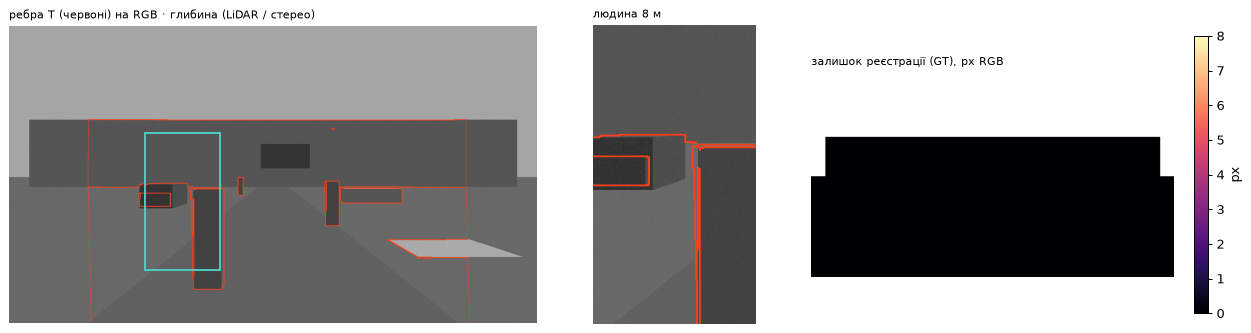

людина 8 м   Z =   8.0 м: залишок  0.00 px, f·B/Z =  7.07 px
людина 18 м  Z =  18.0 м: залишок  0.00 px, f·B/Z =  3.14 px
людина 45 м  Z =  45.0 м: залишок  0.00 px, f·B/Z =  1.26 px
дрон         Z =  60.0 м: залишок  0.00 px, f·B/Z =  0.94 px
стіна        Z =  75.0 м: залишок  0.00 px, f·B/Z =  0.75 px


In [8]:
td, vd = S.warp_t_to_rgb_depth(t8, D)
ut, vt = S.gt_correspondence(D)
print(f'частка RGB-пікселів, які бачить тепловізор: {vd.mean():.1%} (решта — поза FOV T: маска valid обов’язкова)')
P.registration_panel(static=dict(method='глибина (LiDAR / стерео)', Z0=18.0, crop='людина 8 м'))

## 5. Калібрування підігрітою мішенню
Алюмінієва пластина (ε ≈ 0.07) з колами чорної фарби (ε ≈ 0.95), підігріта до 45 °C. У RGB кола темні на світлому, у LWIR —
гарячі на «холодному» (алюміній відбиває небо). Кола — бо краї в LWIR розмиті, а центроїд кола стійкий до розмиття.

Два набори по 25 поз: **фронтально** (1.6–3.2 м, нахил до ±5°) і **з нахилами** (1.0–2.5 м, до ±30°).
Один seed може випадково виявитися вдалим або невдалим, тож кожен набір калібруємо на 5 незалежних наборах поз.

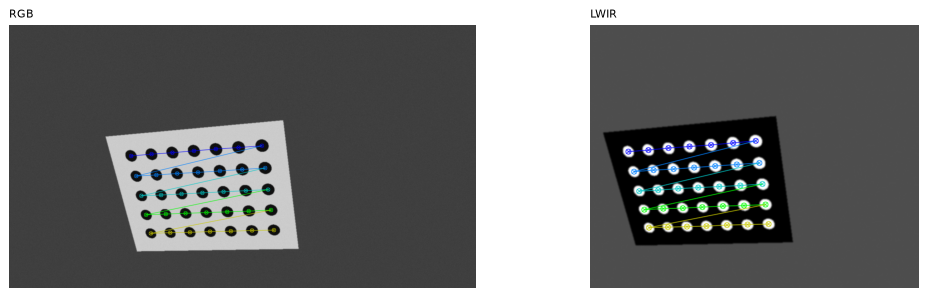

In [9]:
rng = np.random.default_rng(7)
T0 = S.random_target_pose(rng, (1.2, 1.6))
a = S.render_target(S.RGB_CAM, T0, 'rgb', rng=rng); b = S.render_target(S.T_CAM, S.T_T_RGB @ T0, 't', rng=rng)
oka, ca = S.find_circles(a, dark=True); okb, cb = S.find_circles(b, dark=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].imshow(cv2.drawChessboardCorners(cv2.cvtColor(a, cv2.COLOR_GRAY2RGB), (7, 5), ca, oka)); ax[0].set_title('RGB', loc='left', fontsize=9)
ax[1].imshow(cv2.drawChessboardCorners(cv2.cvtColor(b, cv2.COLOR_GRAY2RGB), (7, 5), cb, okb)); ax[1].set_title('LWIR', loc='left', fontsize=9)
for x in ax:
    x.set_axis_off()
plt.tight_layout(); plt.show()

In [10]:
def calibrate(seed, n, dist, tilt):
    rng = np.random.default_rng(seed); obj = S.target_points(); ir, it, ob = [], [], []
    for _ in range(n):
        T = S.random_target_pose(rng, dist, tilt)
        a = S.render_target(S.RGB_CAM, T, 'rgb', rng=rng); b = S.render_target(S.T_CAM, S.T_T_RGB @ T, 't', rng=rng)
        oka, ca = S.find_circles(a, dark=True); okb, cb = S.find_circles(b, dark=False)
        if oka and okb:
            ir.append(ca); it.append(cb); ob.append(obj)
    fl = cv2.CALIB_ZERO_TANGENT_DIST | cv2.CALIB_FIX_K3
    rms_r, Kr, dr, _, _ = cv2.calibrateCamera(ob, ir, (S.RGB_CAM.W, S.RGB_CAM.H), None, None, flags=fl)
    rms_t, Kt, dt, _, _ = cv2.calibrateCamera(ob, it, (S.T_CAM.W, S.T_CAM.H), None, None, flags=fl)
    rms_s, _, _, _, _, R, t, _, _ = cv2.stereoCalibrate(ob, it, ir, Kt, dt, Kr, dr, (S.T_CAM.W, S.T_CAM.H),
                                                        flags=cv2.CALIB_FIX_INTRINSIC)
    return dict(n=len(ob), rms_t=rms_t, rms_s=rms_s, f_t=Kt[0, 0], t=t.ravel(), R=R, Kr=Kr, Kt=Kt,
                dR=Rot.from_matrix(R @ S.T_RGB_T[:3, :3].T).magnitude() * 180 / np.pi)

SETS = {'фронтально': ((1.6, 3.2), 5.0), 'з нахилами': ((1.0, 2.5), 30.0)}
D_wall = S.object_px('стіна')
def wall_residual(c):
    r = S.registration_residual(c['Kr'] @ c['R'] @ np.linalg.inv(c['Kt']), D)
    return np.median(r[D_wall & np.isfinite(r)])

# ~1–2 хв: 2 набори × 5 seed × 25 поз
runs = {k: [calibrate(seed, 25, dist, tilt) for seed in range(5)] for k, (dist, tilt) in SETS.items()}
cal = {k: v[0] for k, v in runs.items()}            # seed 0 — для таблиці на сцені нижче
print(f'GT: f_t = {S.T_CAM.f:.1f} px, t = {S.T_RGB_T[:3, 3]} м')
for k, v in runs.items():
    for seed, c in enumerate(v):
        print(f'{k:10s} seed {seed}: поз {c["n"]}, RMS T {c["rms_t"]:.2f} px, f_t {c["f_t"]:6.1f} px, '
              f't_z {c["t"][2] * 100:+5.1f} см, похибка R {c["dR"]:.2f}°, стіна {wall_residual(c):6.2f} px')
for k, v in runs.items():
    print(f'{k:10s} медіана по 5 seed: RMS T {np.median([c["rms_t"] for c in v]):.2f} px, '
          f'|f_t − GT| {np.median([abs(c["f_t"] - S.T_CAM.f) for c in v]):5.1f} px, '
          f'|t_z| {np.median([abs(c["t"][2]) for c in v]) * 100:4.1f} см, стіна {np.median([wall_residual(c) for c in v]):5.2f} px')

GT: f_t = 772.5 px, t = [0.05 0.01 0.  ] м
фронтально seed 0: поз 25, RMS T 0.29 px, f_t  744.6 px, t_z +10.7 см, похибка R 0.18°, стіна  17.05 px
фронтально seed 1: поз 25, RMS T 0.28 px, f_t  709.2 px, t_z +20.7 см, похибка R 0.31°, стіна  30.71 px


фронтально seed 2: поз 25, RMS T 0.26 px, f_t  614.4 px, t_z +41.2 см, похибка R 1.31°, стіна  77.30 px
фронтально seed 3: поз 25, RMS T 0.32 px, f_t 1023.1 px, t_z -68.8 см, похибка R 0.86°, стіна  77.05 px
фронтально seed 4: поз 25, RMS T 0.23 px, f_t  735.7 px, t_z +15.9 см, похибка R 0.17°, стіна  23.87 px


з нахилами seed 0: поз 23, RMS T 0.08 px, f_t  774.8 px, t_z  -0.4 см, похибка R 0.08°, стіна   0.81 px
з нахилами seed 1: поз 24, RMS T 0.07 px, f_t  773.5 px, t_z  -0.3 см, похибка R 0.03°, стіна   0.61 px
з нахилами seed 2: поз 23, RMS T 0.06 px, f_t  772.1 px, t_z  +0.1 см, похибка R 0.00°, стіна   0.81 px


з нахилами seed 3: поз 24, RMS T 0.07 px, f_t  772.2 px, t_z  +0.1 см, похибка R 0.01°, стіна   0.75 px
з нахилами seed 4: поз 25, RMS T 0.12 px, f_t  772.7 px, t_z  -0.1 см, похибка R 0.11°, стіна   0.78 px


фронтально медіана по 5 seed: RMS T 0.28 px, |f_t − GT|  63.3 px, |t_z| 20.7 см, стіна 30.71 px


з нахилами медіана по 5 seed: RMS T 0.07 px, |f_t − GT|   0.4 px, |t_z|  0.1 см, стіна  0.78 px


In [11]:
# доказ — залишок на сцені, ближні й далекі (як на занятті 11), а не RMS на мішені
print(f'{"набір":8s} | ' + ' | '.join(f'{n:>11s}' for n in ('людина 8 м', 'людина 45 м', 'стіна 75 м', 'край кадру')))
edge = np.zeros_like(D, bool); edge[:, :120] = True; edge &= np.isfinite(D) & (D > 60)
for k, c in cal.items():
    H = c['Kr'] @ c['R'] @ np.linalg.inv(c['Kt'])
    r = S.registration_residual(H, D)
    vals = [np.median(r[S.object_px(n) & np.isfinite(r)]) for n in ('людина 8 м', 'людина 45 м', 'стіна')] + [np.median(r[edge])]
    print(f'{k:8s} | ' + ' | '.join(f'{x:11.2f}' for x in vals))
r = S.registration_residual(S.H_inf(), D)
vals = [np.median(r[S.object_px(n) & np.isfinite(r)]) for n in ('людина 8 м', 'людина 45 м', 'стіна')] + [np.median(r[edge])]
print(f'{"GT H∞":8s} | ' + ' | '.join(f'{x:11.2f}' for x in vals))

набір    |  людина 8 м | людина 45 м |  стіна 75 м |  край кадру
фронтально |       17.16 |        6.32 |       17.05 |       31.09
з нахилами |        6.62 |        0.99 |        0.81 |        0.82


GT H∞    |        7.07 |        1.26 |        0.75 |        0.75


Таблиця — залишок `H∞`, зібраної з каліброваних `K_rgb`, `K_t`, `R` (seed 0), проти тієї самої `H∞` з GT (нижній рядок):
різниця між рядками — це внесок похибки калібрування; спільна частина на 8 м — паралакс, якого `H∞` не знає.

**Що бачимо.** Фронтальні пози дають «гарний» RMS на мішені, але не розв'язують `f` і `t_z`: зміна фокусної відстані
майже не відрізняється від зміни дальності до мішені. Похибка `f` у кілька відсотків — це десятки пікселів на стіні й краях
кадру, і так на кожному seed. Пози ближче і з нахилами розв'язують `f` і `t_z` — залишок на сцені близький до GT.
Правило з заняття 11 тут те саме: валідуйте на ближніх і далеких об'єктах і на краях кадру, а не RMS на мішені.

## 6. Крос-модальні відповідності
Слайд «Реєстрація · мішені і відповідності». Небо в RGB яскраве, у LWIR — найхолодніше; люди навпаки. Градієнти інвертуються,
текстури в T майже немає — ORB-дескриптори не збігаються, NCC від'ємна всюди, а її мінімум — поряд з істиною (полярність інвертована, тож шукати треба
мінімум, і він усе одно неточний). Mutual information не залежить від знаку.

In [12]:
gray = cv2.cvtColor((rgb * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY).astype(np.float32)
tw, valid = S.warp_t_to_rgb(t8, S.H_inf())
orb = cv2.ORB_create(3000)
k1, d1 = orb.detectAndCompute(gray.astype(np.uint8), None); k2, d2 = orb.detectAndCompute(tw.astype(np.uint8), None)
good = [m for m, n in cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(d1, d2, k=2) if m.distance < 0.8 * n.distance]
err = np.hypot(*(np.float32([k1[m.queryIdx].pt for m in good]) - np.float32([k2[m.trainIdx].pt for m in good])).T)
print(f'ORB: {len(k1)} / {len(k2)} точок, {len(good)} пар після ratio test, правильних (< 3 px): {(err < 3).sum()}')

ORB: 249 / 206 точок, 74 пар після ratio test, правильних (< 3 px): 0


MI : максимум у (+6, -4), істина (6, -4); діапазон +0.819 … +1.060
NCC: максимум у (-10, +10), істина (6, -4); діапазон -0.693 … -0.641
NCC: мінімум у (+7, -4) — за 1 px від істини: полярність інвертована, а максимум кореляції взагалі на краю сітки


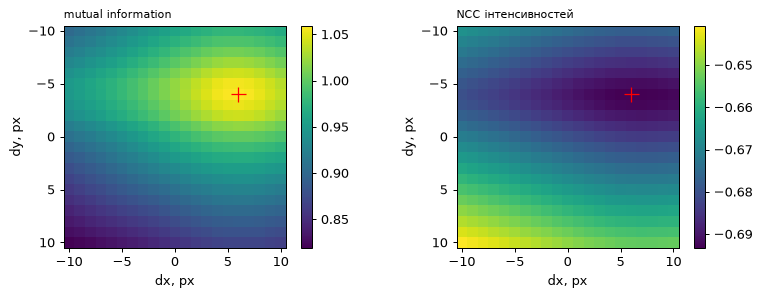

In [13]:
true = (6, -4)                                          # невідомий залишковий зсув, який хочемо знайти
base = S.warp_t_to_rgb_depth(t8, D)[0]                  # точна геометрія + штучний зсув
moved = S.shift_img(base, *true)
grid = range(-10, 11)
MI = np.zeros((21, 21)); NC = np.zeros((21, 21))
for i, dy in enumerate(grid):
    for j, dx in enumerate(grid):
        cand = S.shift_img(moved, -dx, -dy)[40:-40, 40:-40]
        MI[i, j] = S.mutual_information(cand, gray[40:-40, 40:-40], bins=48)
        NC[i, j] = S.ncc(cand, gray[40:-40, 40:-40])
for name, M in (('MI', MI), ('NCC', NC)):
    i, j = np.unravel_index(M.argmax(), M.shape)
    print(f'{name:3s}: максимум у ({list(grid)[j]:+d}, {list(grid)[i]:+d}), істина {true}; діапазон {M.min():+.3f} … {M.max():+.3f}')
i, j = np.unravel_index(NC.argmin(), NC.shape)
print(f'NCC: мінімум у ({list(grid)[j]:+d}, {list(grid)[i]:+d}) — за {np.hypot(list(grid)[j] - true[0], list(grid)[i] - true[1]):.0f} px '
      f'від істини: полярність інвертована, а максимум кореляції взагалі на краю сітки')
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for a, (name, M) in zip(ax, (('mutual information', MI), ('NCC інтенсивностей', NC))):
    im = a.imshow(M, extent=(-10.5, 10.5, 10.5, -10.5), cmap='viridis'); a.plot(*true, 'r+', ms=12)
    a.set_title(name, loc='left', fontsize=9); a.set_xlabel('dx, px'); a.set_ylabel('dy, px'); plt.colorbar(im, ax=a, fraction=0.04)
plt.tight_layout(); plt.show()

In [14]:
# з H∞ замість точної геометрії MI знаходить «середню» глибину сцени — паралакс поглинається зсувом
moved2 = S.shift_img(tw, *true)
M2 = np.zeros((21, 21))
for i, dy in enumerate(grid):
    for j, dx in enumerate(grid):
        M2[i, j] = S.mutual_information(S.shift_img(moved2, -dx, -dy)[40:-40, 40:-40], gray[40:-40, 40:-40], bins=48)
i, j = np.unravel_index(M2.argmax(), M2.shape)
print(f'MI поверх H∞: ({list(grid)[j]:+d}, {list(grid)[i]:+d}) замість {true} — зсув «з’їв» паралакс ближньої частини кадру')

MI поверх H∞: (+3, -5) замість (6, -4) — зсув «з’їв» паралакс ближньої частини кадру


### Реальні пари: ORB, NCC, MI і градієнти на LLVIP і FLIR-aligned
Та сама перевірка на реальних парах. ORB — на одній парі FLIR-aligned. Далі для 30 випадкових пар кожного датасету
зсуваємо T на відомий вектор (3, −2) px сітки 320×256 і рахуємо, у скількох парах метод знаходить його (±1 px):
MI інтенсивностей, максимум і мінімум NCC інтенсивностей, NCC і MI **модулів градієнта** (модуль не залежить від полярності).

ORB, реальна пара FLIR-aligned: 2399 / 2737 точок, 43 пар після ratio test, правильних (< 3 px): 0


частка пар, де знайдено (3, −2)    MI інтенсивн.         NCC max         NCC min  NCC градієнтів   MI градієнтів
LLVIP test                                   43%              7%             13%             93%            100%
FLIR-aligned val                             57%             13%             13%             50%             40%


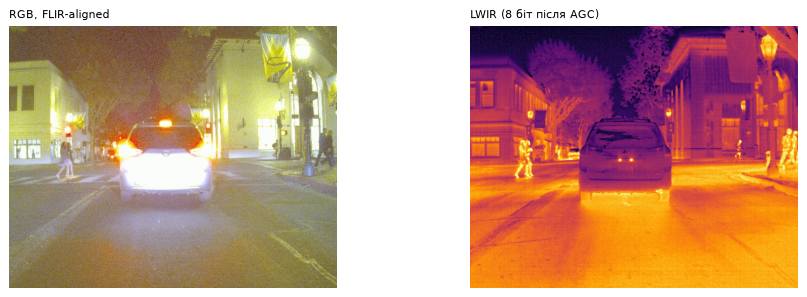

In [15]:
import rgbt12 as R
if R.available():
    pairs = R.flir_pairs('validation')
    rgb_r, t_r = R.read_pair(pairs[len(pairs) // 3])
    g_r = cv2.cvtColor(rgb_r, cv2.COLOR_RGB2GRAY)
    k1, d1 = orb.detectAndCompute(g_r, None); k2, d2 = orb.detectAndCompute(t_r, None)
    good = [m for m, n in cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(d1, d2, k=2) if m.distance < 0.8 * n.distance]
    err = np.hypot(*(np.float32([k1[m.queryIdx].pt for m in good]) - np.float32([k2[m.trainIdx].pt for m in good])).T)
    print(f'ORB, реальна пара FLIR-aligned: {len(k1)} / {len(k2)} точок, {len(good)} пар після ratio test, правильних (< 3 px): {(err < 3).sum()}')
    names = {'mi': 'MI інтенсивн.', 'ncc': 'NCC max', 'ncc_min': 'NCC min', 'grad': 'NCC градієнтів', 'grad_mi': 'MI градієнтів'}
    rec = {name: R.shift_recovery(ps) for name, ps in (('LLVIP test', R.llvip_pairs('test')), ('FLIR-aligned val', R.flir_pairs('validation')))}
    print(f'{"частка пар, де знайдено (3, −2)":32s}' + ''.join(f'{v:>16s}' for v in names.values()))
    for name, r in rec.items():
        print(f'{name:32s}' + ''.join(f'{r[m]:16.0%}' for m in names))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    ax[0].imshow(rgb_r); ax[1].imshow(t_r, cmap='inferno')
    for a, tt in zip(ax, ('RGB, FLIR-aligned', 'LWIR (8 біт після AGC)')):
        a.set_title(tt, loc='left', fontsize=9); a.set_axis_off()
    plt.tight_layout(); plt.show()
else:
    print(f'Реальних даних немає — завантажте: {R.FETCH}')

**Що бачимо.** ORB на реальній парі так само дає нуль правильних відповідностей. NCC інтенсивностей марна
в обидва боки: полярність у реальних сценах змішана (люди світлі, небо темне, фари яскраві в RGB). MI на реальних кадрах
не така бездоганна, як на синтетиці: AGC і текстури RGB дають плаский рельєф. Модуль градієнта найнадійніший на LLVIP,
але на денних FLIR із низьким тепловим контрастом (Demo 1) і він помиляється. Висновок для монітора реєстрації в полі:
одна пара кадрів — не вимір, агрегуйте зсув по багатьох кадрах і відкидайте пари з пласким піком.

### Скільки розбіжності лишається у «вирівняних» датасетах
LLVIP вирівняний апаратно і гомографією, FLIR-aligned — вручну, глобальним перетворенням для кожної пари. Глобальне
вирівнювання не прибирає паралакс близьких об'єктів (розділ 2) і похибку ручної роботи. Для 120 випадкових пар кожного
датасету шукаємо зсув T перебором ±6 px на сітці 320×256 двома способами: MI інтенсивностей і NCC **модулів градієнта**
(модуль не залежить від полярності: людина світла в T і темна в RGB дає однаковий край). Пік на межі перебору — ненадійний.

In [16]:
if R.available():
    for name, pairs, k in (('LLVIP test', R.llvip_pairs('test'), 4), ('FLIR-aligned val', R.flir_pairs('validation'), 2)):
        for method in ('mi', 'grad'):
            m = R.misalignment(pairs, (320, 256), r=6, n=120, method=method)
            ok = m[:, 3] == 0
            d = np.hypot(m[ok, 0], m[ok, 1]) * k                     # у px нативного кадру
            print(f'{name:17s} {"MI інтенсивн." if method == "mi" else "NCC градієнтів":15s}: пік на межі в {1 - ok.mean():4.0%} пар; '
                  f'решта — |зсув| p50 {np.median(d):4.1f} px, p95 {np.percentile(d, 95):5.1f} px нативного кадру '
                  f'(= {np.percentile(d, 95) / (2 * k):.1f} px сітки 160×128)')
else:
    print(f'Реальних даних немає — завантажте: {R.FETCH}')

LLVIP test        MI інтенсивн.  : пік на межі в  19% пар; решта — |зсув| p50  5.7 px, p95  12.9 px нативного кадру (= 1.6 px сітки 160×128)


LLVIP test        NCC градієнтів : пік на межі в   0% пар; решта — |зсув| p50  4.0 px, p95   5.7 px нативного кадру (= 0.7 px сітки 160×128)


FLIR-aligned val  MI інтенсивн.  : пік на межі в  12% пар; решта — |зсув| p50  4.0 px, p95   9.7 px нативного кадру (= 2.4 px сітки 160×128)


FLIR-aligned val  NCC градієнтів : пік на межі в   3% пар; решта — |зсув| p50  2.8 px, p95   8.2 px нативного кадру (= 2.1 px сітки 160×128)


**Що бачимо.** MI сирих інтенсивностей на реальних кадрах інколи дає плаский рельєф і пік на межі — модуль градієнта
стійкіший. «Вирівняний» датасет має ненульову залишкову розбіжність у пікселях нативного кадру — це та сама похибка
реєстрації, яку Demo 4 моделює зсувом T. Отже бюджет реєстрації треба порівнювати не з нулем, а з розподілом,
який ви виміряли на своїх даних, і під нього підбирати аугментацію зсувом.

## 7. Час: `f·ω·Δt`
Домашнє питання із заняття 11. Обидві камери по 30 Гц без спільного тригера: фази незалежні, тож найгірша пара за найближчою міткою —
½ періоду = 16.7 мс. Додайте τ мікроболометра ≈ 10 мс — це ще й систематичне запізнення T-кадру.

In [17]:
for omega, dt in ((30, 0.0167), (30, 0.010), (90, 0.0167), (300, 0.005)):
    for f, n in ((S.RGB_CAM.f, 'RGB'), (S.T_CAM.f, 'T')):
        print(f'ω = {omega:3d} °/с, Δt = {dt * 1e3:4.1f} мс → {S.sync_shift_px(f, omega, dt):5.1f} px на сітці {n}', end='   ')
    print()
rng = np.random.default_rng(0)
t_rgb = np.arange(0, 10, 1 / 30) + rng.uniform(0, 1 / 30)
t_t = np.arange(0, 10, 1 / 30) + rng.uniform(0, 1 / 30) + rng.normal(0, 0.0005, 300)
j, dt = S.pair_nearest(t_rgb, t_t)
print(f'пари за найближчою міткою: медіана |Δt| {np.median(dt) * 1e3:.1f} мс, максимум {dt.max() * 1e3:.1f} мс (межа — ½ періоду 16.7 мс)')

ω =  30 °/с, Δt = 16.7 мс →   9.7 px на сітці RGB   ω =  30 °/с, Δt = 16.7 мс →   6.8 px на сітці T   
ω =  30 °/с, Δt = 10.0 мс →   5.8 px на сітці RGB   ω =  30 °/с, Δt = 10.0 мс →   4.0 px на сітці T   
ω =  90 °/с, Δt = 16.7 мс →  29.1 px на сітці RGB   ω =  90 °/с, Δt = 16.7 мс →  20.3 px на сітці T   
ω = 300 °/с, Δt =  5.0 мс →  29.0 px на сітці RGB   ω = 300 °/с, Δt =  5.0 мс →  20.2 px на сітці T   
пари за найближчою міткою: медіана |Δt| 12.3 мс, максимум 13.8 мс (межа — ½ періоду 16.7 мс)


In [18]:
P.sync_panel();

interactive(children=(FloatSlider(value=30.0, continuous_update=False, description='omega_dps', max=300.0, ste…

## Питання

1. Для вашого гімбала (f і B): з якої дальності `H∞` дає < 1 px? А для zoom ×4?
2. Чому `t_z` погано визначається з далеких фронтальних поз мішені? Яку позу додати першою?
3. Online-підстройка MI поверх `H∞` «знайшла» зсув. Чому після цього ближні цілі зареєстровані гірше, а не краще?
4. Що дешевше для вашої платформи: апаратний тригер обох ядер чи глибина для точної реєстрації?